# Customer Churn & Retention Analytics
*Understanding Customer Behavior, Churn Patterns & Retention Opportunities*

**Author:** Shravani Wagh

## 1. Project Introduction
Customer churn means a customer stops using a service. For a subscription business it matters because keeping an existing customer is usually cheaper than finding a new one.

This notebook analyses `train.csv`, a customer dataset with 8,000 rows. The target column is `Churn` (0 = retained, 1 = churned). The goal is to describe how churn is spread across customer groups and to point out segments that may need a closer look. No prediction model is built here.

One thing to keep in mind throughout: every result below is an **observed pattern**. None of it shows that a variable *causes* churn.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

RETAINED, CHURNED = "#12a594", "#e5484d"   # colours used for the two churn groups
NEUTRAL = "#4f46e5"

## 3. Load the Dataset

In [2]:
df = pd.read_csv("../data/train.csv")
df.head()

,Customer_ID,Age,Gender,Location,Subscription_Type,Account_Age_Months,Monthly_Spending,Total_Usage_Hours,Support_Calls,Late_Payments,Streaming_Usage,Discount_Used,Satisfaction_Score,Last_Interaction_Type,Complaint_Tickets,Promo_Opted_In,Churn
0,1001,19,Male,Illinois,Basic,50,152.44,416,5,2,61,76,3,Neutral,0,1,1
1,1002,41,Male,California,Premium,14,113.34,36,5,1,17,90,5,Negative,3,0,0
2,1003,44,Female,Florida,Basic,2,168.39,207,3,1,85,12,6,Neutral,3,0,1
3,1004,21,Male,Florida,Basic,55,197.12,379,4,3,54,32,4,Positive,3,1,0
4,1005,65,Male,New York,Premium,12,84.46,475,5,4,82,62,1,Neutral,0,0,1


## 4. Dataset Shape

In [3]:
print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])
print()
print(list(df.columns))

Rows   : 8000
Columns: 17

['Customer_ID', 'Age', 'Gender', 'Location', 'Subscription_Type', 'Account_Age_Months', 'Monthly_Spending', 'Total_Usage_Hours', 'Support_Calls', 'Late_Payments', 'Streaming_Usage', 'Discount_Used', 'Satisfaction_Score', 'Last_Interaction_Type', 'Complaint_Tickets', 'Promo_Opted_In', 'Churn']


## 5. Missing Value Check

In [4]:
missing = df.isna().sum()
print("Total missing values:", missing.sum())
missing[missing > 0]

Total missing values: 0


Series([], dtype: int64)

## 6. Duplicate Check

In [5]:
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate Customer_IDs:", df["Customer_ID"].duplicated().sum())

Duplicate rows       : 0
Duplicate Customer_IDs: 0


## 7. Data Types and Basic Information

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            8000 non-null   int64  
 1   Age                    8000 non-null   int64  
 2   Gender                 8000 non-null   str    
 3   Location               8000 non-null   str    
 4   Subscription_Type      8000 non-null   str    
 5   Account_Age_Months     8000 non-null   int64  
 6   Monthly_Spending       8000 non-null   float64
 7   Total_Usage_Hours      8000 non-null   int64  
 8   Support_Calls          8000 non-null   int64  
 9   Late_Payments          8000 non-null   int64  
 10  Streaming_Usage        8000 non-null   int64  
 11  Discount_Used          8000 non-null   int64  
 12  Satisfaction_Score     8000 non-null   int64  
 13  Last_Interaction_Type  8000 non-null   str    
 14  Complaint_Tickets      8000 non-null   int64  
 15  Promo_Opted_In 

In [7]:
print("Churn values:", sorted(df["Churn"].unique()))
for col in ["Gender", "Location", "Subscription_Type", "Last_Interaction_Type"]:
    print(f"{col}: {sorted(df[col].unique())}")

Churn values: [np.int64(0), np.int64(1)]
Gender: ['Female', 'Male']
Location: ['California', 'Florida', 'Illinois', 'New York', 'Texas']
Subscription_Type: ['Basic', 'Enterprise', 'Premium']
Last_Interaction_Type: ['Negative', 'Neutral', 'Positive']


## 8. Descriptive Statistics

In [8]:
df.drop(columns=["Customer_ID"]).describe().T

,count,mean,std,min,25%,50%,75%,max
Age,"8,000.00",43.54,14.91,18.00,31.00,44.00,57.00,69.00
Account_Age_Months,"8,000.00",30.16,16.94,1.00,15.00,30.00,45.00,59.00
Monthly_Spending,"8,000.00",104.80,54.64,10.09,57.64,104.69,151.70,199.94
Total_Usage_Hours,"8,000.00",254.33,140.86,10.00,133.00,256.50,376.00,499.00
Support_Calls,"8,000.00",4.45,2.89,0.00,2.00,4.00,7.00,9.00
Late_Payments,"8,000.00",1.99,1.40,0.00,1.00,2.00,3.00,4.00
Streaming_Usage,"8,000.00",49.80,28.97,0.00,24.00,51.00,75.00,99.00
Discount_Used,"8,000.00",49.43,28.66,0.00,25.00,50.00,74.00,99.00
Satisfaction_Score,"8,000.00",5.46,2.88,1.00,3.00,5.00,8.00,10.00
Complaint_Tickets,"8,000.00",1.97,1.41,0.00,1.00,2.00,3.00,4.00


The numeric columns all have sensible ranges (for example monthly spending runs from about 10 to 200, satisfaction from 1 to 10), so no cleaning or outlier removal was needed.

## 9. Churn Distribution

Total customers    : 8,000
Churned customers  : 2,505
Retained customers : 5,495
Overall churn rate : 31.31%


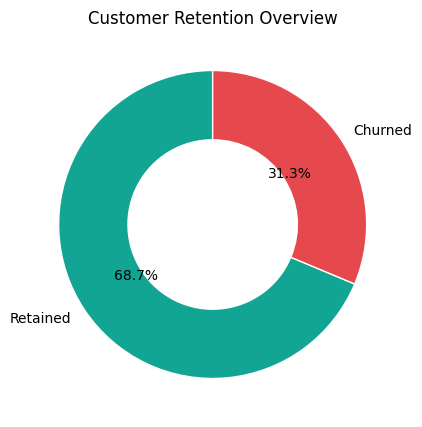

In [9]:
n_total = len(df)
n_churned = int(df["Churn"].sum())
n_retained = n_total - n_churned
churn_rate = n_churned / n_total * 100

print(f"Total customers    : {n_total:,}")
print(f"Churned customers  : {n_churned:,}")
print(f"Retained customers : {n_retained:,}")
print(f"Overall churn rate : {churn_rate:.2f}%")

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie([n_retained, n_churned], labels=["Retained", "Churned"], colors=[RETAINED, CHURNED],
       autopct="%1.1f%%", startangle=90, wedgeprops={"width": 0.45, "edgecolor": "white"})
ax.set_title("Customer Retention Overview")
plt.show()

About one customer in three has churned (31.31%). The classes are not perfectly balanced, but both groups are large enough to compare.

## 10. Helper Function for Churn Rates
Most of the analysis below asks the same question: *what share of customers in each group churned?* A small helper keeps that consistent. It also returns the group size, because a churn rate from a very small group is not reliable.

In [10]:
def churn_by(data, col, order=None):
    out = data.groupby(col, observed=True)["Churn"].agg(customers="size", churned="sum", churn_rate="mean")
    out["churn_rate"] = out["churn_rate"] * 100
    if order is not None:
        out = out.reindex(order)
    return out


def bar_rate(table, title, xlabel, horizontal=False, sort=False, ax=None):
    t = table.sort_values("churn_rate", ascending=False) if sort else table
    ax = ax or plt.subplots(figsize=(6, 3.8))[1]
    labels = t.index.astype(str)
    if horizontal:
        ax.barh(labels, t["churn_rate"], color=NEUTRAL)
        ax.invert_yaxis()
        for i, v in enumerate(t["churn_rate"]):
            ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
        ax.set_xlabel("Churn rate (%)")
    else:
        ax.bar(labels, t["churn_rate"], color=NEUTRAL)
        for i, v in enumerate(t["churn_rate"]):
            ax.text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=9)
        ax.set_ylabel("Churn rate (%)")
        ax.set_xlabel(xlabel)
    # dashed line = overall churn rate, so the groups can be compared against it
    (ax.axvline if horizontal else ax.axhline)(churn_rate, color=CHURNED, ls="--", lw=1)
    ax.set_title(title)
    return ax

## 11. Categorical Analysis
Gender, last interaction type and promo opt-in are not part of the main dashboard charts, but they are worth a quick look.

In [11]:
for col in ["Gender", "Last_Interaction_Type", "Promo_Opted_In"]:
    print(churn_by(df, col).round(2), "\n")

        customers  churned  churn_rate
Gender                                
Female       4035     1280       31.72
Male         3965     1225       30.90

 

                       customers  churned  churn_rate
Last_Interaction_Type                                
Negative                    2650      835       31.51
Neutral                     2700      834       30.89
Positive                    2650      836       31.55 

                customers  churned  churn_rate
Promo_Opted_In                                
0                    4002     1285       32.11
1                    3998     1220       30.52 



The differences are small. For example, the two gender groups are within about one percentage point of each other.

## 12. Numerical Analysis
Average of each numeric column for retained and churned customers.

In [12]:
num_cols = ["Age", "Account_Age_Months", "Monthly_Spending", "Total_Usage_Hours", "Support_Calls",
            "Late_Payments", "Streaming_Usage", "Discount_Used", "Satisfaction_Score", "Complaint_Tickets"]
compare = df.groupby("Churn")[num_cols].mean().T
compare.columns = ["Retained", "Churned"]
compare["Difference"] = compare["Churned"] - compare["Retained"]
compare

,Retained,Churned,Difference
Age,43.71,43.18,-0.53
Account_Age_Months,30.13,30.25,0.12
Monthly_Spending,104.47,105.55,1.08
Total_Usage_Hours,254.69,253.52,-1.17
Support_Calls,4.48,4.40,-0.08
Late_Payments,2.01,1.96,-0.05
Streaming_Usage,49.97,49.42,-0.55
Discount_Used,49.03,50.29,1.26
Satisfaction_Score,5.42,5.55,0.12
Complaint_Tickets,1.98,1.95,-0.03


Retained and churned customers have very similar averages in every column. Nothing here separates the two groups clearly.

## 13. KPI Summary
These are the same headline numbers shown on the dashboard.

In [13]:
kpis = pd.Series({
    "Total customers": f"{n_total:,}",
    "Churned customers": f"{n_churned:,}",
    "Retained customers": f"{n_retained:,}",
    "Overall churn rate": f"{churn_rate:.2f}%",
    "Average monthly spending": f"{df['Monthly_Spending'].mean():.2f}",
    "Average usage hours": f"{df['Total_Usage_Hours'].mean():.2f}",
    "Average satisfaction score": f"{df['Satisfaction_Score'].mean():.2f}",
})
kpis.to_frame("Value")

,Value
Total customers,"8,000"
Churned customers,"2,505"
Retained customers,"5,495"
Overall churn rate,31.31%
Average monthly spending,104.80
Average usage hours,254.33
Average satisfaction score,5.46


## 14. Churn by Subscription Type

,customers,churned,churn_rate
Subscription_Type,,,
Basic,4063,1280,31.50
Enterprise,817,255,31.21
Premium,3120,970,31.09


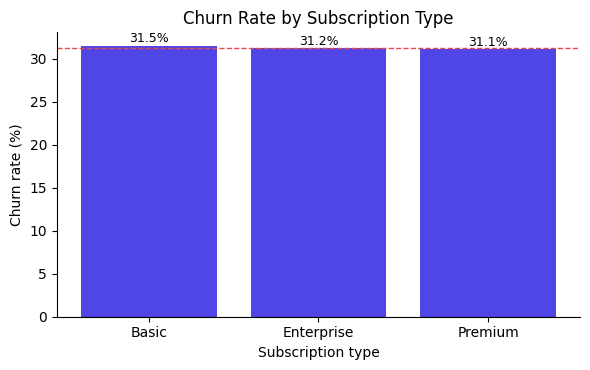

In [14]:
sub = churn_by(df, "Subscription_Type").sort_values("churn_rate", ascending=False)
display(sub.round(2))
bar_rate(sub, "Churn Rate by Subscription Type", "Subscription type")
plt.tight_layout(); plt.show()

The three subscription types are within half a percentage point of each other, so subscription type does not separate churners from retained customers here.

## 15. Churn by Location

,customers,churned,churn_rate
Location,,,
Florida,1557,504,32.37
California,1597,508,31.81
Texas,1603,506,31.57
New York,1619,509,31.44
Illinois,1624,478,29.43


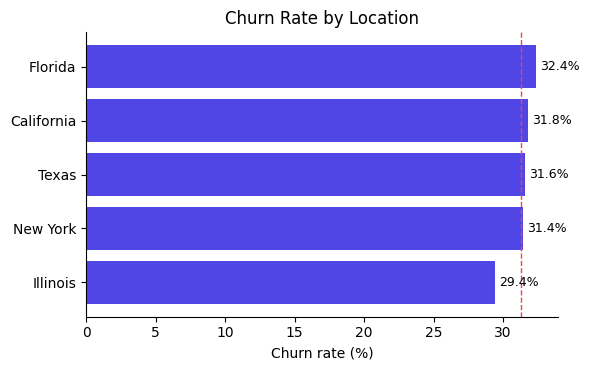

In [15]:
loc = churn_by(df, "Location").sort_values("churn_rate", ascending=False)
display(loc.round(2))
bar_rate(loc, "Churn Rate by Location", "", horizontal=True)
plt.tight_layout(); plt.show()

Florida has the highest observed churn (32.37%) and Illinois the lowest (29.43%). The gap is about three percentage points. It is an observed difference only; the data cannot say why it exists.

## 16. Churn by Account Age
`Account_Age_Months` is grouped into 12-month bands. The data goes up to 59 months, so the last band (49–60) holds customers aged 49 to 59 months.

,customers,churned,churn_rate
Account_Age_Group,,,
0–12 Months,1615,485,30.03
13–24 Months,1595,495,31.03
25–36 Months,1633,532,32.58
37–48 Months,1653,532,32.18
49–60 Months,1504,461,30.65


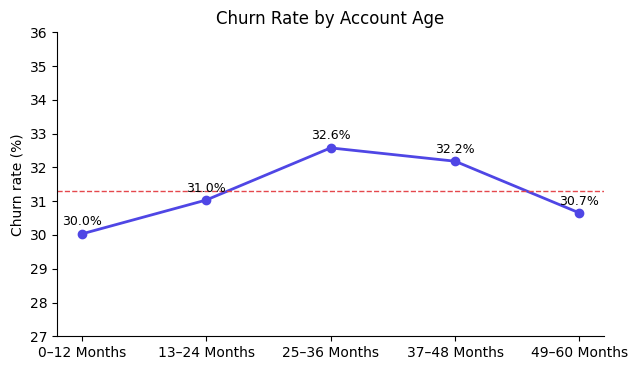

In [16]:
age_labels = ["0–12 Months", "13–24 Months", "25–36 Months", "37–48 Months", "49–60 Months"]
df["Account_Age_Group"] = pd.cut(df["Account_Age_Months"], bins=[-1, 12, 24, 36, 48, 60], labels=age_labels)
age = churn_by(df, "Account_Age_Group")
display(age.round(2))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(age.index.astype(str), age["churn_rate"], marker="o", color=NEUTRAL, lw=2)
for i, v in enumerate(age["churn_rate"]):
    ax.text(i, v + 0.25, f"{v:.1f}%", ha="center", fontsize=9)
ax.axhline(churn_rate, color=CHURNED, ls="--", lw=1)
ax.set_ylim(27, 36); ax.set_ylabel("Churn rate (%)"); ax.set_title("Churn Rate by Account Age")
plt.tight_layout(); plt.show()

The 25–36 month (32.58%) and 37–48 month (32.18%) groups are a little higher than the rest. The shape is a gentle rise and fall, not a steady trend. The y-axis here starts at 27% to make the small differences visible, so the gaps look bigger than they are.

## 17. Churn by Spending Group
Monthly spending is split into four groups using the same boundaries as the dashboard: 0–50 Low, 50–100 Medium, 100–150 High, 150–200 Very High.

,customers,churned,churn_rate
Spending_Group,,,
Low,1675,510,30.45
Medium,2119,660,31.15
High,2139,682,31.88
Very High,2067,653,31.59


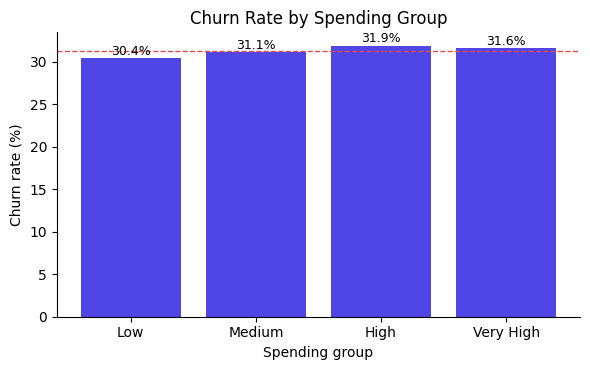

In [17]:
df["Spending_Group"] = pd.cut(df["Monthly_Spending"], bins=[0, 50, 100, 150, 200],
                              labels=["Low", "Medium", "High", "Very High"])
spend = churn_by(df, "Spending_Group")
display(spend.round(2))
bar_rate(spend, "Churn Rate by Spending Group", "Spending group")
plt.tight_layout(); plt.show()

Churn is between 30.45% and 31.88% across the four groups. Higher spending groups are slightly higher, but the differences are small.

## 18. Churn by Satisfaction Score

,customers,churned,churn_rate
Satisfaction_Score,,,
1,825,244,29.58
2,816,248,30.39
3,819,243,29.67
4,787,254,32.27
5,791,251,31.73
6,783,241,30.78
7,809,260,32.14
8,793,248,31.27
9,793,255,32.16


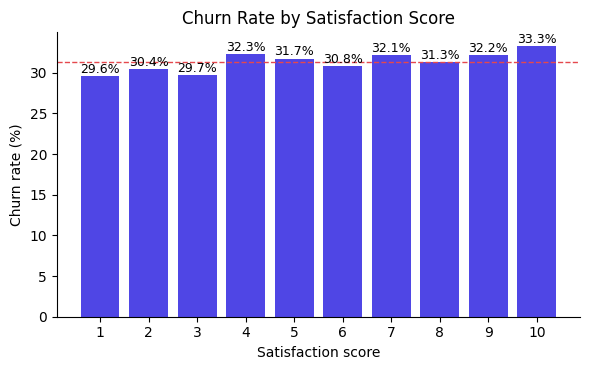

In [18]:
sat = churn_by(df, "Satisfaction_Score")
display(sat.round(2))
bar_rate(sat, "Churn Rate by Satisfaction Score", "Satisfaction score")
plt.tight_layout(); plt.show()

Churn does not fall as satisfaction rises. The lowest churn is at score 1 (29.58%) and the highest at score 10 (33.29%), and the values in between go up and down. This is not a clean pattern and should not be read as 'satisfaction affects churn'.

## 19. Churn by Support Calls

,customers,churned,churn_rate
Support_Calls,,,
0,871,278,31.92
1,808,261,32.30
2,779,252,32.35
3,772,238,30.83
4,795,232,29.18
5,786,268,34.10
6,844,253,29.98
7,767,258,33.64
8,801,239,29.84


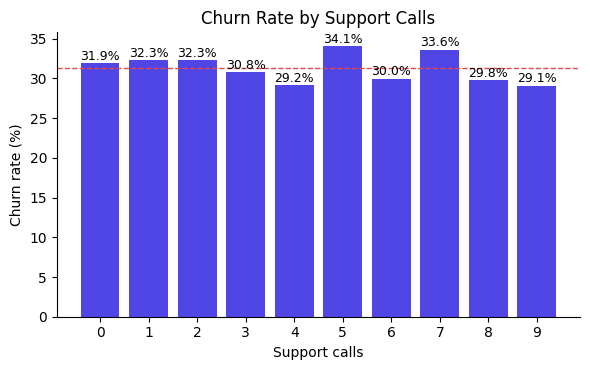

In [19]:
calls = churn_by(df, "Support_Calls")
display(calls.round(2))
bar_rate(calls, "Churn Rate by Support Calls", "Support calls")
plt.tight_layout(); plt.show()

Rates range from 29.09% (9 calls) to 34.10% (5 calls) with no steady direction. Each group has roughly 770 to 870 customers, so some of this movement is probably ordinary variation.

## 20. Correlation Analysis
Pearson correlation between each numeric column and `Churn` (0/1). Values near 0 mean almost no linear relationship.

,Correlation with Churn
Discount_Used,0.02
Satisfaction_Score,0.02
Monthly_Spending,0.01
Account_Age_Months,0.00
Customer_ID,-0.00
Total_Usage_Hours,-0.00
Streaming_Usage,-0.01
Complaint_Tickets,-0.01
Support_Calls,-0.01
Age,-0.02


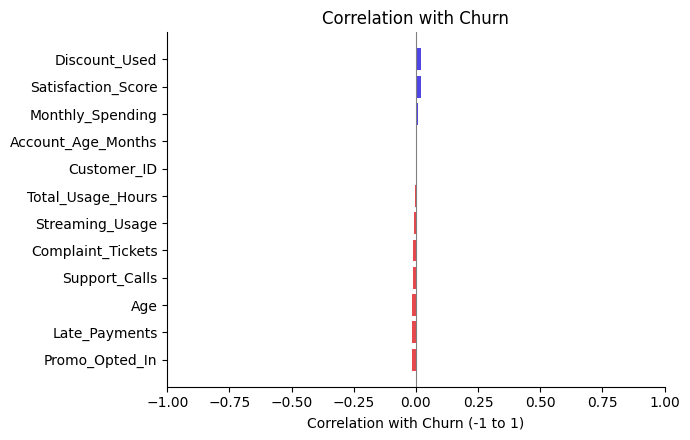

In [20]:
num_all = df.select_dtypes(include="number").columns.drop("Churn")
corr = df[num_all].corrwith(df["Churn"]).sort_values(ascending=False)
display(corr.round(4).to_frame("Correlation with Churn"))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(corr.index, corr.values, color=[NEUTRAL if v >= 0 else CHURNED for v in corr.values])
ax.invert_yaxis(); ax.axvline(0, color="grey", lw=0.8)
ax.set_xlim(-1, 1); ax.set_xlabel("Correlation with Churn (-1 to 1)")
ax.set_title("Correlation with Churn")
plt.tight_layout(); plt.show()

All correlations are between about -0.02 and +0.02. That is very weak. `Customer_ID` is only an identifier and is shown just for completeness. These values should not be read as evidence of causation.

## 21. Spending vs Usage

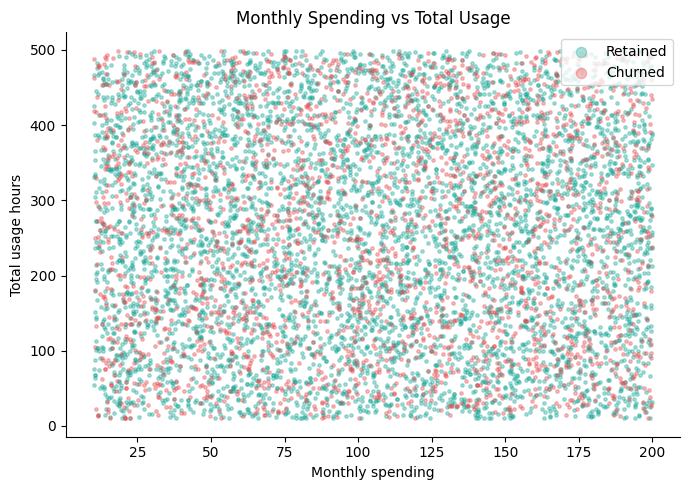

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))
for value, name, colour in [(0, "Retained", RETAINED), (1, "Churned", CHURNED)]:
    s = df[df["Churn"] == value]
    ax.scatter(s["Monthly_Spending"], s["Total_Usage_Hours"], s=6, alpha=0.35, color=colour, label=name)
ax.set_xlabel("Monthly spending"); ax.set_ylabel("Total usage hours")
ax.set_title("Monthly Spending vs Total Usage"); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

The two colours are completely mixed. Churned and retained customers do not form separate groups on these two variables.

## 22. All Churn Breakdowns Together
A summary view of the six main breakdowns, using the same dashed overall-rate line.

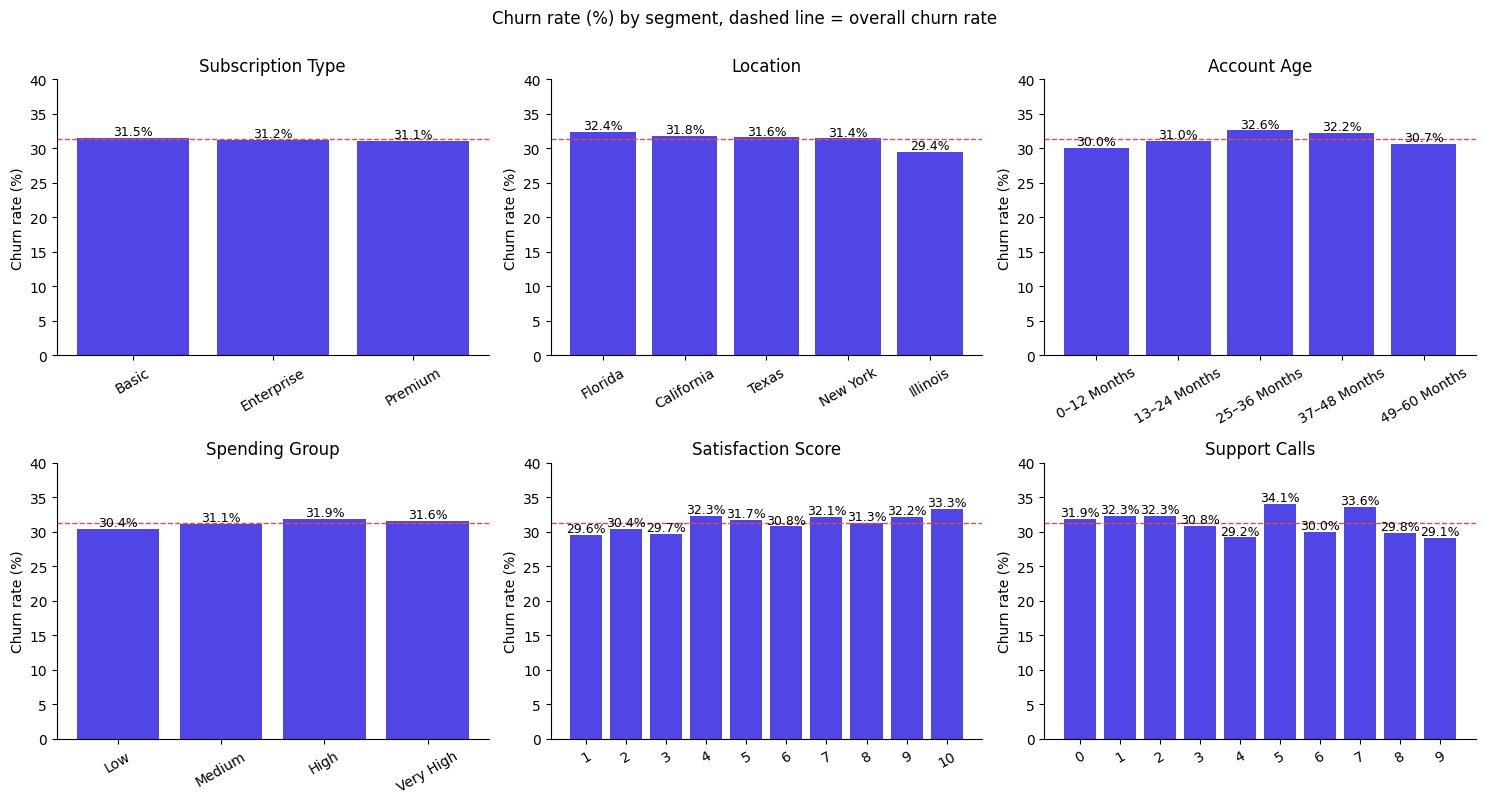

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
bar_rate(sub, "Subscription Type", "", ax=axes[0, 0])
bar_rate(loc, "Location", "", ax=axes[0, 1])
bar_rate(age, "Account Age", "", ax=axes[0, 2])
bar_rate(spend, "Spending Group", "", ax=axes[1, 0])
bar_rate(sat, "Satisfaction Score", "", ax=axes[1, 1])
bar_rate(calls, "Support Calls", "", ax=axes[1, 2])
for a in axes.flat:
    a.set_ylim(0, 40); a.tick_params(axis="x", labelrotation=30)
fig.suptitle("Churn rate (%) by segment, dashed line = overall churn rate", y=1.0)
plt.tight_layout(); plt.show()

## 23. Business Insights
- Overall churn is 31.31%, roughly 1 in 3 customers.
- Florida shows the highest observed churn by location (32.37%) and Illinois the lowest (29.43%).
- Customers with 25–36 months (32.58%) and 37–48 months (32.18%) of account age show relatively higher churn than newer or older accounts.
- The High spending group has about 31.88% churn, slightly above the Low group (30.45%).
- Satisfaction score 10 has the highest churn among the scores (33.29%), and support-call count 5 has 34.10%. Neither follows a steady pattern.
- Subscription types are very similar (31.09% to 31.50%).
- Correlations with churn are all extremely weak.

Taken together: churn is spread fairly evenly across the customer base. No single variable stands out as a driver.

## 24. Recommendations
These follow from the observed patterns only.
1. **Look at mid-lifecycle customers.** The 25–48 month group is slightly higher. Check whether a retention offer for that group is worth testing.
2. **Investigate the location gap.** Find out whether pricing, service quality, competition or customer mix differ between Florida and Illinois.
3. **Review support interactions.** Some call counts show higher churn. Look at what the calls were about and how they ended before drawing any conclusion.
4. **Segment campaigns.** Since no single factor stands out, combine several (location, account age, spending, engagement) instead of one blanket strategy.
5. **Do deeper analysis next.** Customer segmentation, classification models, feature importance, cohort analysis and survival analysis would be the logical next steps. None of these has been done in this project.

## 25. Final Conclusion
Out of 8,000 customers, 2,505 churned, an overall rate of 31.31%. Churn rates by subscription, location, account age, spending, satisfaction and support calls all sit in a narrow band of roughly 29% to 34%, and the correlations with churn are all close to zero.

So the honest conclusion is that this dataset does not show a strong standalone churn driver. Some segments (Florida, 25–48 month accounts) are slightly higher than average and could be a starting point for further investigation, but these are small differences and are not evidence of cause. A multi-factor approach would be more suitable than looking at one variable at a time.

**Limitations:** the dataset is a single snapshot with no dates, so trends over time cannot be studied. The reasons customers left are not recorded. No significance testing was done, so small differences between groups may be due to chance.